# STEP 2 - Data Dictionary and Leakage Audit

**Goal:** understand every one of the 32 columns: its type, how many values are missing, how many distinct values it has,
and - most important - whether it is **safe to use as a feature**.

**Why now:** Step 1 only looked at the data. Before any cleaning or modelling we need a per-column fact sheet,
and we need to test the leakage suspects with evidence instead of opinion.

**Libraries:** pandas (tables), numpy (numbers/NaN), matplotlib (charts, saved as SVG only).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

DATA = Path('..') / '..' / 'data' / 'hotel_bookings.csv'
FIG = Path('figures')          # every chart in this project is saved as SVG only
FIG.mkdir(exist_ok=True)

df = pd.read_csv(DATA)
print(df.shape)

(119390, 32)


## Part A - Column profile (the raw facts)

For every column: data type, count of missing values, % missing, number of distinct values, and one example.
**Why:** missing counts tell us where cleaning is needed; distinct counts separate IDs/categories (few values)
from continuous numbers (many values) and warn about high-cardinality columns that are hard to encode.

In [2]:
profile = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(),
    'example': df.apply(lambda s: s.dropna().iloc[0]),
})
profile

,dtype,missing,missing_pct,n_unique,example
hotel,object,0,0.00,2,Resort Hotel
is_canceled,int64,0,0.00,2,0
lead_time,int64,0,0.00,479,342
arrival_date_year,int64,0,0.00,3,2015
arrival_date_month,object,0,0.00,12,July
arrival_date_week_number,int64,0,0.00,53,27
arrival_date_day_of_month,int64,0,0.00,31,1
stays_in_weekend_nights,int64,0,0.00,17,0
stays_in_week_nights,int64,0,0.00,35,0
adults,int64,0,0.00,14,2


## Part B - Missing values chart

**Why a chart:** a number like 94.3% is easy to forget; a bar chart shows at a glance which columns are a real problem.

children     0.00
country      0.41
agent       13.69
company     94.31
Name: missing_pct, dtype: float64


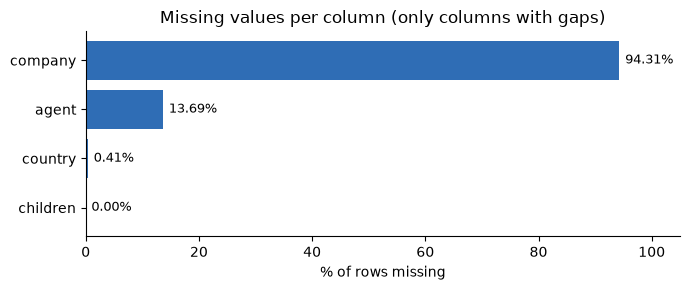

In [3]:
miss = profile.loc[profile['missing'] > 0, 'missing_pct'].sort_values()
print(miss)

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(miss.index, miss.values, color='#2F6DB5')
ax.set_xlabel('% of rows missing')
ax.set_title('Missing values per column (only columns with gaps)')
ax.set_xlim(0, 105)
for b, v in zip(bars, miss.values):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f'{v:.2f}%', va='center', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / 'step2_missing_values.svg')
plt.show()

## Part C - Hidden missing values and category codes

pandas only counts true blanks as missing. Text such as `Undefined` is a **disguised missing value**: present in the file,
but it means "unknown". We list every value of each low-cardinality text column to find them and to verify what the codes really are.

In [4]:
text_cols = [c for c in df.select_dtypes('object').columns if c not in ('reservation_status_date',)]
for c in text_cols:
    vc = df[c].value_counts(dropna=False)
    print(f'--- {c}  ({df[c].nunique()} distinct) ---')
    print(vc.head(12).to_string())
    print()

--- hotel  (2 distinct) ---
hotel
City Hotel      79330
Resort Hotel    40060

--- arrival_date_month  (12 distinct) ---
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
December      6780
January       5929

--- meal  (5 distinct) ---
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798

--- country  (177 distinct) ---
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
USA     2097
CHE     1730

--- market_segment  (8 distinct) ---
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2

--- distribution_channel  (5 distinct) ---
distribution_channel
TA/TO

## Part D - Numeric summary

`describe()` gives min, max, mean and quartiles. **Why:** impossible values (negative counts, absurd maximums) and
suspicious zeros show up in min and max long before any chart does.

In [5]:
num_cols = df.select_dtypes('number').columns
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


## Part E - Leakage audit

**Leakage test:** *"At the moment a booking is made, would I really know this value?"* If not, it cannot be a feature.
We test each suspect with data, not opinion.

### E1. reservation_status vs is_canceled

In [6]:
pd.crosstab(df['reservation_status'], df['is_canceled'], margins=True)

is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


### E2. reservation_status_date - is it an after-the-fact date?

We rebuild the departure date (arrival date + nights stayed). If for Check-Out rows the status date equals the departure date,
the column is recorded *after the stay*, so it cannot be known when the booking is made.

In [7]:
arrival = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-' + df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d')
nights = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
departure = arrival + pd.to_timedelta(nights, unit='D')
status_date = pd.to_datetime(df['reservation_status_date'])

co = df['reservation_status'] == 'Check-Out'
print('Check-Out rows where status date == departure date: '
      f'{(status_date[co] == departure[co]).mean():.4f}')

ca = df['reservation_status'] == 'Canceled'
days_before = (arrival[ca] - status_date[ca]).dt.days
print('Canceled rows: status date is BEFORE arrival for', f'{(days_before > 0).mean():.4f}', 'of rows')
print('Median days between cancellation date and arrival:', days_before.median())

Check-Out rows where status date == departure date: 0.9996
Canceled rows: status date is BEFORE arrival for 0.9795 of rows
Median days between cancellation date and arrival: 56.0


### E2b. How much does this date alone give away?

Define `gap = reservation_status_date - arrival_date` (in days). A cancellation happens BEFORE or ON the arrival date (gap <= 0).
A completed stay ends AFTER arrival (gap > 0). So one simple rule - *"gap <= 0 means cancelled"* - needs no model at all.

In [8]:
gap = (status_date - arrival).dt.days
rule_pred = (gap <= 0).astype(int)          # the whole 'model': cancelled if the date is on/before arrival
print('Accuracy of the one-line rule  gap <= 0  ->  cancelled:', round((rule_pred == df['is_canceled']).mean(), 4))
print('Baseline (always predict not cancelled)                :', round((df['is_canceled'] == 0).mean(), 4))
print()
print(pd.crosstab(rule_pred.rename('rule says cancelled'), df['is_canceled'], margins=True))

Accuracy of the one-line rule  gap <= 0  ->  cancelled: 0.9941
Baseline (always predict not cancelled)                : 0.6296

is_canceled              0      1     All
rule says cancelled                      
0                    74460      0   74460
1                      706  44224   44930
All                  75166  44224  119390


### E3. Suspects: assigned_room_type, booking_changes, days_in_waiting_list

For each suspect we compare the **cancellation rate** across groups. A huge gap is a *signal* - but a signal is not the same as leakage.
Leakage depends on **timing**: was the value known when the prediction is needed?

In [9]:
df['room_changed'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)

def rate(by, name=None):
    t = df.groupby(by)['is_canceled'].agg(rows='size', cancel_rate='mean').round(4)
    t.index.name = name or (by if isinstance(by, str) else None)
    return t

print('room_changed (reserved != assigned)'); print(rate('room_changed')); print()
print('booking_changes (capped at 3+)'); print(rate(df['booking_changes'].clip(upper=3), 'booking_changes')); print()
print('days_in_waiting_list > 0'); print(rate(df['days_in_waiting_list'].gt(0).astype(int), 'waiting>0')); print()
print('deposit_type'); print(rate('deposit_type'))

room_changed (reserved != assigned)
                rows  cancel_rate
room_changed                     
0             104473       0.4156
1              14917       0.0538

booking_changes (capped at 3+)
                   rows  cancel_rate
booking_changes                     
0                101314       0.4085
1                 12701       0.1423
2                  3805       0.2013
3                  1570       0.1656

days_in_waiting_list > 0
             rows  cancel_rate
waiting>0                     
0          115692       0.3619
1            3698       0.6379

deposit_type
                rows  cancel_rate
deposit_type                     
No Deposit    104641       0.2838
Non Refund     14587       0.9936
Refundable       162       0.2222


### E4. The evidence as a chart

Dashed line = overall cancellation rate (37.04%). Bars far from the line mean the group behaves very differently - a strong signal.
Whether that signal is *legitimate* or *leakage* is decided by timing, which is why we need the verdict in Part F.

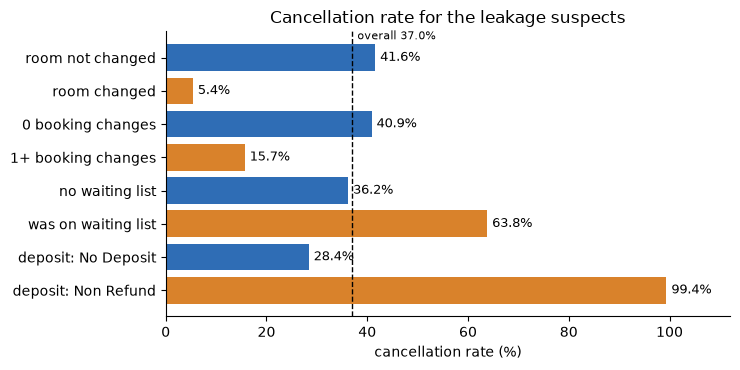

In [10]:
groups = {
    'room not changed': df.loc[df['room_changed'] == 0, 'is_canceled'].mean(),
    'room changed': df.loc[df['room_changed'] == 1, 'is_canceled'].mean(),
    '0 booking changes': df.loc[df['booking_changes'] == 0, 'is_canceled'].mean(),
    '1+ booking changes': df.loc[df['booking_changes'] >= 1, 'is_canceled'].mean(),
    'no waiting list': df.loc[df['days_in_waiting_list'] == 0, 'is_canceled'].mean(),
    'was on waiting list': df.loc[df['days_in_waiting_list'] > 0, 'is_canceled'].mean(),
    'deposit: No Deposit': df.loc[df['deposit_type'] == 'No Deposit', 'is_canceled'].mean(),
    'deposit: Non Refund': df.loc[df['deposit_type'] == 'Non Refund', 'is_canceled'].mean(),
}
overall = df['is_canceled'].mean()
colors = ['#2F6DB5', '#D9822B'] * 4

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(groups))[::-1]
ax.barh(y, [v * 100 for v in groups.values()], color=colors)
ax.set_yticks(y)
ax.set_yticklabels(list(groups.keys()))
ax.axvline(overall * 100, color='black', linestyle='--', linewidth=1)
ax.text(overall * 100 + 1, y.max() + 0.55, f'overall {overall:.1%}', fontsize=8)
for yi, v in zip(y, groups.values()):
    ax.text(v * 100 + 1, yi, f'{v:.1%}', va='center', fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel('cancellation rate (%)')
ax.set_title('Cancellation rate for the leakage suspects')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / 'step2_suspect_cancel_rates.svg')
plt.show()

## Part F - Leakage re-audit of ALL columns

So far we tested suspects one by one, by logic. A careful audit also uses a second, data-driven check, so we do not miss a column.

**The idea (single-feature screen):** for each column, train a tiny decision tree (depth 5) that sees ONLY that one column, and measure how well it predicts
`is_canceled` using cross-validated **ROC-AUC** (5 folds). AUC is 0.5 for random guessing and 1.0 for perfect prediction.
A column that alone gets a near-perfect AUC is almost certainly leaking the answer.

**Limit of this screen:** it detects *how strong* a column is, not *when* it becomes known. A strong but legitimate column (like lead_time) also scores high.
So the screen tells us where to look; the timing logic decides. We use both.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

feature_cols = [c for c in df.columns if c not in ('is_canceled', 'room_changed')]
y = df['is_canceled']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = {}
for c in feature_cols:
    s = df[c]
    if s.dtype == 'object':
        x = pd.factorize(s, sort=True)[0]          # text -> integer codes (sorted, so ISO dates keep their order)
    else:
        x = s.fillna(-1).to_numpy()                # NaN -> -1 so the tree can still use the column
    tree = DecisionTreeClassifier(max_depth=5, random_state=42)
    scores[c] = cross_val_score(tree, np.asarray(x).reshape(-1, 1), y, cv=cv, scoring='roc_auc').mean()

screen = pd.Series(scores).sort_values(ascending=False).round(4)
print(screen.to_string())

reservation_status                1.0000
country                           0.6954
lead_time                         0.6905
deposit_type                      0.6634
reservation_status_date           0.6381
market_segment                    0.6361
total_of_special_requests         0.6355
agent                             0.6269
adr                               0.6095
assigned_room_type                0.6023
distribution_channel              0.5708
booking_changes                   0.5699
hotel                             0.5667
stays_in_week_nights              0.5660
previous_cancellations            0.5639
customer_type                     0.5609
required_car_parking_spaces       0.5493
arrival_date_week_number          0.5449
adults                            0.5381
arrival_date_month                0.5357
reserved_room_type                0.5338
company                           0.5280
arrival_date_day_of_month         0.5235
days_in_waiting_list              0.5206
previous_booking

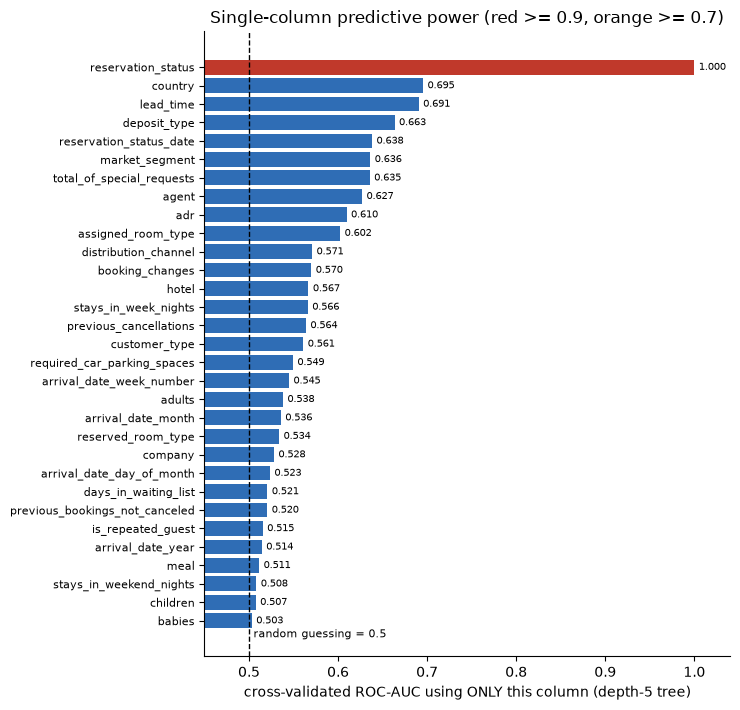

In [12]:
s_plot = screen.sort_values()
bar_colors = ['#C0392B' if v >= 0.9 else ('#D9822B' if v >= 0.7 else '#2F6DB5') for v in s_plot.values]

fig, ax = plt.subplots(figsize=(7.5, 7.2))
ax.barh(s_plot.index, s_plot.values, color=bar_colors)
ax.axvline(0.5, color='black', linestyle='--', linewidth=1)
ax.text(0.505, -0.9, 'random guessing = 0.5', fontsize=8)
for yi, v in enumerate(s_plot.values):
    ax.text(v + 0.005, yi, f'{v:.3f}', va='center', fontsize=7.5)
ax.set_xlim(0.45, 1.04)
ax.set_xlabel('cross-validated ROC-AUC using ONLY this column (depth-5 tree)')
ax.set_title('Single-column predictive power (red >= 0.9, orange >= 0.7)')
ax.tick_params(axis='y', labelsize=8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / 'step2_single_feature_auc.svg')
plt.show()

### F1b. The screen's blind spot: leakage hidden in a RELATIONSHIP between two columns

`reservation_status_date` scored only about 0.64 on its own, yet we proved it is a near-perfect leak. The leak appears only when we combine
columns: `gap = status_date - arrival_date`. We also test `room_changed = (reserved_room_type != assigned_room_type)`.
Same screen, on these two derived columns. Expect `gap` to jump, while `room_changed` stays modest because it only applies to the ~12.5% of bookings whose room changed
(its leakage is decided by timing and mechanism, not by overall strength).

In [13]:
pair_features = {'gap (status_date - arrival_date)': gap, 'room_changed': df['room_changed']}
for name, x in pair_features.items():
    auc = cross_val_score(DecisionTreeClassifier(max_depth=5, random_state=42),
                          x.fillna(-1).to_numpy().reshape(-1, 1), y, cv=cv, scoring='roc_auc').mean()
    print(f'{name:40s} AUC = {auc:.4f}')

gap (status_date - arrival_date)         AUC = 0.9998
room_changed                             AUC = 0.5848


### F2. Checking the columns we have not yet looked at: parking, special requests, guest history, adr

These are the remaining columns whose timing is unclear. We look at the cancellation rate inside each group.

In [14]:
print('required_car_parking_spaces'); print(rate(df['required_car_parking_spaces'].clip(upper=2), 'parking spaces (2 = 2+)')); print()
print('total_of_special_requests'); print(rate(df['total_of_special_requests'].clip(upper=3), 'special requests (3 = 3+)')); print()
print('previous_cancellations > 0'); print(rate(df['previous_cancellations'].gt(0).astype(int), 'prev cancellations>0')); print()
print('is_repeated_guest'); print(rate('is_repeated_guest')); print()
print('adr == 0 (share of rows) by outcome:')
print(df.assign(adr_zero=df['adr'].eq(0)).groupby('is_canceled')['adr_zero'].mean().round(4).to_string()); print()
print('mean adr by outcome:'); print(df.groupby('is_canceled')['adr'].mean().round(2).to_string())

required_car_parking_spaces
                           rows  cancel_rate
parking spaces (2 = 2+)                     
0                        111974       0.3949
1                          7383       0.0000
2                            33       0.0000

total_of_special_requests
                            rows  cancel_rate
special requests (3 = 3+)                    
0                          70318       0.4772
1                          33226       0.2202
2                          12969       0.2210
3                           2877       0.1682

previous_cancellations > 0
                        rows  cancel_rate
prev cancellations>0                     
0                     112906       0.3391
1                       6484       0.9164

is_repeated_guest
                     rows  cancel_rate
is_repeated_guest                     
0                  115580       0.3779
1                    3810       0.1449

adr == 0 (share of rows) by outcome:
is_canceled
0    0.0232
1    0.0048

## Part G - The data dictionary with a verdict for every column

Verdict labels:
- **USABLE** - known at booking time, no problem seen yet.
- **NEEDS CARE** - usable only after a decision (missing values, outliers, odd values, or timing that must be checked).
- **LEAKAGE** - contains the answer or is only known after the outcome. Excluded from features.
- **TARGET** - a column we predict (`is_canceled` for classification, `adr` for regression).

These verdicts are our current judgment from the evidence above. Ablation experiments later will test the "NEEDS CARE" ones with scores.

In [15]:
verdict = {
    'hotel': ('USABLE', 'Chosen at booking. Two values.'),
    'is_canceled': ('TARGET', 'Classification target. 1 includes both Canceled (43,017) and No-Show (1,207).'),
    'lead_time': ('USABLE', 'Known at booking. Skewed, max 737 days; check outliers in EDA.'),
    'arrival_date_year': ('NEEDS CARE', 'Only 2015-2017. A model cannot generalise to a year it never saw; decide how to split by time.'),
    'arrival_date_month': ('USABLE', 'Known at booking. Text month names need ordering/encoding.'),
    'arrival_date_week_number': ('NEEDS CARE', 'Overlaps with month: redundant information, check correlation.'),
    'arrival_date_day_of_month': ('USABLE', 'Known at booking, probably weak alone.'),
    'stays_in_weekend_nights': ('NEEDS CARE', 'Planned stay known at booking, but max 19 and zero-night stays exist (Step 3).'),
    'stays_in_week_nights': ('NEEDS CARE', 'Planned stay known at booking, but max 50 and zero-night stays exist (Step 3).'),
    'adults': ('NEEDS CARE', 'Known at booking, but zero-adult rows and max 55 exist (Step 3).'),
    'children': ('NEEDS CARE', '4 missing values (stored as NaN, hence float).'),
    'babies': ('USABLE', 'Known at booking. Max 10 looks odd; check in Step 3.'),
    'meal': ('NEEDS CARE', "'Undefined' (1,169 rows) is a disguised missing value."),
    'country': ('NEEDS CARE', '488 missing; 177 distinct values (high cardinality); PRT is about 41% of rows.'),
    'market_segment': ('NEEDS CARE', "'Undefined' appears in 2 rows; overlaps with distribution_channel."),
    'distribution_channel': ('NEEDS CARE', "'Undefined' appears in 5 rows; overlaps with market_segment."),
    'is_repeated_guest': ('USABLE', 'Guest history, known at booking.'),
    'previous_cancellations': ('USABLE', 'Guest history, known at booking. Heavily skewed; any previous cancellation -> 91.6% cancel (strong but legitimate).'),
    'previous_bookings_not_canceled': ('USABLE', 'Guest history, known at booking. Heavily skewed.'),
    'reserved_room_type': ('USABLE', 'Chosen at booking time.'),
    'assigned_room_type': ('LEAKAGE', 'Assigned at check-in. Room changed -> 5.4% cancel vs 41.6%: a room can only be reassigned for guests who arrive.'),
    'booking_changes': ('NEEDS CARE', 'LEAKAGE SUSPECT: final count includes changes made after booking (always 0 at booking time). Test by ablation.'),
    'deposit_type': ('NEEDS CARE', 'Non Refund shows 99.36% cancellation: opposite of common sense. Investigate before trusting.'),
    'agent': ('NEEDS CARE', '13.69% missing; these are IDs (333 distinct), not quantities. Missing may mean "no agent".'),
    'company': ('NEEDS CARE', '94.31% missing; IDs, not quantities. Likely reduce to a has-company flag or drop.'),
    'days_in_waiting_list': ('NEEDS CARE', 'LEAKAGE SUSPECT on timing: known only after the waiting period. Waiting>0 -> 63.8% cancel.'),
    'customer_type': ('USABLE', 'Known at booking. Four values.'),
    'adr': ('NEEDS CARE', 'Regression TARGET. As a feature for cancellation it is quoted at booking, but has min -6.38 and max 5400.'),
    'required_car_parking_spaces': ('LEAKAGE', 'All 7,416 bookings with 1+ spaces have 0 cancellations (exactly 0.00%): parking is only recorded for guests who arrive.'),
    'total_of_special_requests': ('NEEDS CARE', 'Requests can be added after booking (timing suspect). 0 requests -> 47.7% cancel, 3+ -> 16.8%: a gradual pattern, not a perfect split.'),
    'reservation_status': ('LEAKAGE', 'Canceled/No-Show map exactly to is_canceled = 1. It IS the answer.'),
    'reservation_status_date': ('LEAKAGE', 'For Canceled rows it is the cancellation date; for Check-Out rows it equals departure date (99.96%).'),
}
original_cols = set(df.columns) - {'room_changed'}   # room_changed is a helper column we created in E3
assert set(verdict) == original_cols, original_cols ^ set(verdict)

dictionary = profile.copy()
dictionary['verdict'] = [verdict[c][0] for c in dictionary.index]
dictionary['reason'] = [verdict[c][1] for c in dictionary.index]
dictionary.index.name = 'column'
dictionary.to_csv('STEP_2_column_dictionary.csv')

print(dictionary['verdict'].value_counts().to_string())
dictionary[['verdict', 'reason']]

verdict
NEEDS CARE    17
USABLE        10
LEAKAGE        4
TARGET         1


,verdict,reason
column,,
hotel,USABLE,Chosen at booking. Two values.
is_canceled,TARGET,Classification target. 1 includes both Cancele...
lead_time,USABLE,"Known at booking. Skewed, max 737 days; check ..."
arrival_date_year,NEEDS CARE,Only 2015-2017. A model cannot generalise to a...
arrival_date_month,USABLE,Known at booking. Text month names need orderi...
arrival_date_week_number,NEEDS CARE,"Overlaps with month: redundant information, ch..."
arrival_date_day_of_month,USABLE,"Known at booking, probably weak alone."
stays_in_weekend_nights,NEEDS CARE,"Planned stay known at booking, but max 19 and ..."
stays_in_week_nights,NEEDS CARE,"Planned stay known at booking, but max 50 and ..."


## Summary of Step 2

- Real missing values exist in 4 columns only: `children` (4), `country` (488), `agent` (16,340), `company` (112,593).
- Hidden missing values (`Undefined`) exist in `meal`, `market_segment`, `distribution_channel`.
- **No-Show is counted as cancelled** in `is_canceled`.
- Leakage confirmed with evidence: `reservation_status`, `reservation_status_date`, `assigned_room_type`, `required_car_parking_spaces` (found in the re-audit).
- Leakage suspects to settle by ablation: `booking_changes`, `days_in_waiting_list`, `total_of_special_requests`.
- The single-column screen only caught `reservation_status`. The date leak hides in a relationship between columns (`gap` AUC 0.9998 vs 0.638 for the raw date), so logic and pair checks are essential. `assigned_room_type` is a partial leak (room_changed AUC 0.585): it is excluded because of timing and mechanism, not strength.
- Counter-intuitive pattern to investigate: `deposit_type = Non Refund` cancels 99.36% of the time.
- Oddities queued for Step 3: adr = -6.38 and 5400, adults up to 55, zero-night stays, zero-adult rows.